<a href="https://colab.research.google.com/github/a01770768-oss/JobishViri/blob/main/prestacion_viri_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Running Habits in Mexico: How Does Age Relate to Running Frequency? Viridiana Hurtado

**TABLE OF CONTENTS**

1. [Initial Setup](#scrollTo=3VhkF8sh4DEk)
2. [RQ1: Which age group represents the largest share of respondents? — Pie chart](#scrollTo=WiOv3ycP4DEo)
3. [RQ2: How often do respondents run per week? — Bar chart](#scrollTo=VcjS6qh74DEr&line=1&uniqifier=1)
4. [RQ3: How are respondents' ages distributed? — Histogram](#scrollTo=1cb8a034&line=1&uniqifier=1)
5. [RQ4: Does age differ across running-frequency groups? — Boxplot](#scrollTo=9b33a6c1&line=1&uniqifier=1)
6. [RQ5: How is running frequency distributed within each age group? — Heatmap](#scrollTo=f0b40980&line=1&uniqifier=1)
7. [RQ6: How does average running frequency change across age groups? — Line chart](#scrollTo=5df83425&line=1&uniqifier=1)
8. [RQ7: Which age group has the highest share of frequent runners? — Lollipop chart](#scrollTo=bb405d17&line=1&uniqifier=1)
9. [RQ8: Is age associated with estimated weekly running days? — Simple regression](#scrollTo=17683d26&line=1&uniqifier=1)
10. [Final Conclusions](#scrollTo=bf4694bb&line=1&uniqifier=1)


##[ 1. Initial Setup](#scrollTo=e8aNrmQz4DEg&line=5&uniqifier=1)

### Description of DATASET

This dataset contains 60 simulated survey responses about running habits in Mexico.

Each row represents one respondent and records the respondent's age and reported weekly running-frequency category.

- **Source:** Simulated survey dataset used for this analysis.
- **Observations:** 60 respondents.
- **Original variables:** 2.
- **Unit of observation:** One respondent.

### Variables of Interest

- **Age:** Age of each respondent in years. Numerical variable.
- **Running_frequency:** Reported weekly running frequency. Categorical ordinal variable.
- **AgeGP:** Age group created from `Age`. Categorical variable.
- **RunScore:** Ordered score created from `Running_frequency` for comparison across age groups.
- **RunDays_est:** Approximate weekly running days used only for the simple regression study.


In [ ]:

file_path = 'https://raw.githubusercontent.com/a01770768-oss/Running-Viri/main/correr_mexico_datos.csv'

import pandas as pd

df = pd.read_csv(file_path)
df.head()


,Age,Running_frequency
0,49,3-4 days
1,38,1-2 days
2,53,3-4 days
3,17,1-2 days
4,30,3-4 days


In [ ]:
df.columns

Index(['Age', 'Running_frequency'], dtype='object')

In [ ]:
favs = ['Age', 'Running_frequency']
ndf = df[favs]
ndf.head()

,Age,Running_frequency
0,49,3-4 days
1,38,1-2 days
2,53,3-4 days
3,17,1-2 days
4,30,3-4 days


In [ ]:
ndf.shape

(60, 2)

In [ ]:
ndf = ndf.dropna()
ndf.isnull().any()

,0
Age,False
Running_frequency,False


In [ ]:
def age_cls(x):
    if x < 20:
        return 'Under 20'
    elif x < 30:
        return '20-29'
    elif x < 40:
        return '30-39'
    return '40+'

In [ ]:
ndf['AgeGP'] = ndf['Age'].apply(age_cls)
ndf.head()

,Age,Running_frequency,AgeGP
0,49,3-4 days,40+
1,38,1-2 days,30-39
2,53,3-4 days,40+
3,17,1-2 days,Under 20
4,30,3-4 days,30-39


# Summary of Research Questions

In [27]:
roadmap = pd.DataFrame({
    'Study': [1, 2, 3, 4, 5, 6, 7, 8],

    'Research Question': [
        'Which age group represents the largest share of respondents?',
        'How often do respondents run per week?',
        "How are respondents' ages distributed?",
        'Does age differ across running-frequency groups?',
        'How is running frequency distributed within each age group?',
        'How does average running frequency change across age groups?',
        'Which age group has the highest share of frequent runners?',
        'Is age associated with estimated weekly running days?'
    ],

    'Figure': [
        'Pie chart',
        'Bar chart',
        'Histogram',
        'Boxplot',
        'Heatmap',
        'Line chart',
        'Lollipop chart',
        'Regression + scatterplot'
    ]
})

roadmap

,Study,Research Question,Figure
0,1,Which age group represents the largest share o...,Pie chart
1,2,How often do respondents run per week?,Bar chart
2,3,How are respondents' ages distributed?,Histogram
3,4,Does age differ across running-frequency groups?,Boxplot
4,5,How is running frequency distributed within ea...,Heatmap
5,6,How does average running frequency change acro...,Line chart
6,7,Which age group has the highest share of frequ...,Lollipop chart
7,8,Is age associated with estimated weekly runnin...,Regression + scatterplot


[2. RQ1: Which age group represents the largest share of respondents?](#scrollTo=e8aNrmQz4DEg&line=6&uniqifier=1)

In [ ]:
age_counts = pd.pivot_table(ndf, index='AgeGP', values='Age', aggfunc='count')
age_counts

,Age
AgeGP,
20-29,15
30-39,16
40+,24
Under 20,5


In [10]:
age_counts.rename(columns={'Age':'Count'}, inplace=True)
age_counts.reset_index(inplace=True)
age_counts

,AgeGP,Count
0,20-29,15
1,30-39,16
2,40+,24
3,Under 20,5


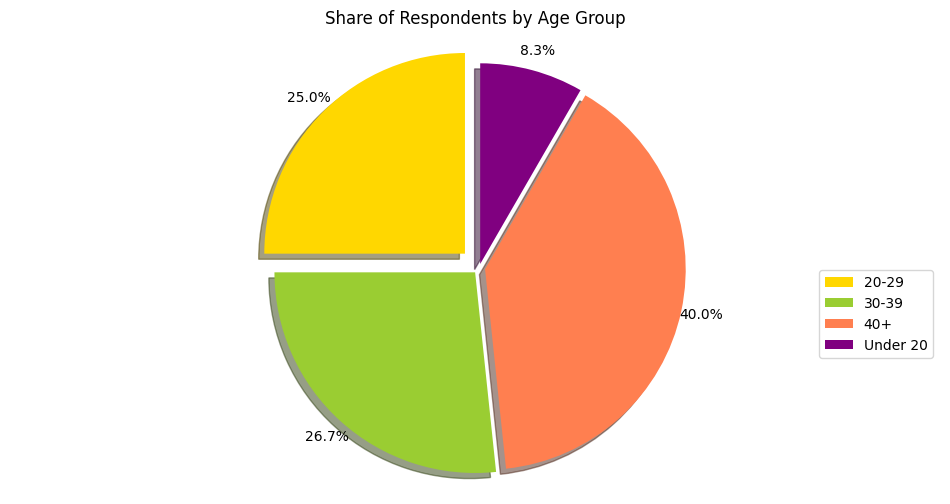

In [11]:
import matplotlib.pyplot as plt

explode_list = [0.1, 0.03, 0.03, 0.02]
colors = ['gold', 'yellowgreen', 'coral', 'purple']

age_counts['Count'].plot(
    kind='pie',
    figsize=(12, 6),
    autopct='%1.1f%%',
    startangle=90,
    shadow=True,
    labels=None,
    pctdistance=1.1,
    explode=explode_list,
    colors=colors
)

plt.axis('equal')
plt.legend(
    labels=age_counts['AgeGP'],
    bbox_to_anchor=(1, 0.5)
)
plt.title('Share of Respondents by Age Group')
plt.ylabel('')
plt.show()

**Insights**

1. The 40+ group is the largest segment of the sample, so the overall running patterns are influenced more by older respondents than by the youngest group.
2. This imbalance matters for the rest of the analysis: comparisons by age group are more informative than relying only on the overall sample because the groups are not equally represented.


##[3. RQ2: How often do respondents run per week?](#scrollTo=e8aNrmQz4DEg&line=6&uniqifier=1)

In [12]:
frequency_counts = pd.pivot_table(ndf, index='Running_frequency',
                                  values='Age', aggfunc='count')
frequency_counts

,Age
Running_frequency,
0 days,8
1-2 days,29
3-4 days,14
5+ days,9


In [13]:
frequency_counts.rename(columns={'Age':'Count'}, inplace=True)
frequency_counts.reset_index(inplace=True)
frequency_counts

,Running_frequency,Count
0,0 days,8
1,1-2 days,29
2,3-4 days,14
3,5+ days,9


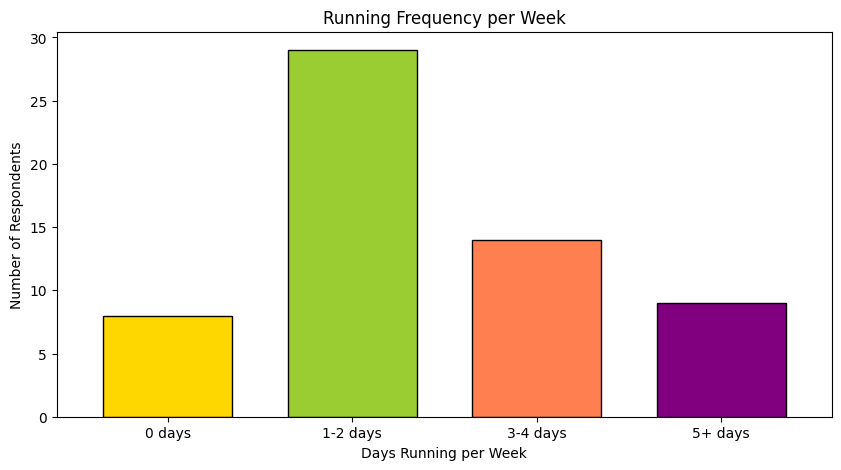

In [14]:
import matplotlib.pyplot as plt

colors = ['gold', 'yellowgreen', 'coral', 'purple']

frequency_counts['Count'].plot(
    kind='bar',
    figsize=(10, 5),
    color=colors,
    edgecolor='black',
    width=0.7
)

plt.title('Running Frequency per Week')
plt.xlabel('Days Running per Week')
plt.ylabel('Number of Respondents')

plt.xticks(
    ticks=range(len(frequency_counts)),
    labels=frequency_counts['Running_frequency'],
    rotation=0
)

plt.show()

**Insights**

1. Running 1–2 days per week is the dominant behavior, showing that the typical respondent is an occasional or moderate runner rather than a high-frequency runner.
2. Because the most common behavior is not intensive running, the next studies examine whether age helps explain which respondents move toward more frequent running categories.


In [15]:

freq_order = ['0 days', '1-2 days', '3-4 days', '5+ days']

score_map = {
    '0 days': 0,
    '1-2 days': 1,
    '3-4 days': 2,
    '5+ days': 3
}

days_map = {
    '0 days': 0,
    '1-2 days': 1.5,
    '3-4 days': 3.5,
    '5+ days': 5.5
}

ndf['RunScore'] = ndf['Running_frequency'].map(score_map)
ndf['RunDays_est'] = ndf['Running_frequency'].map(days_map)

age_order = ['Under 20', '20-29', '30-39', '40+']
ndf['AgeGP'] = pd.Categorical(ndf['AgeGP'], categories=age_order, ordered=True)
ndf['Running_frequency'] = pd.Categorical(
    ndf['Running_frequency'],
    categories=freq_order,
    ordered=True
)

ndf.head()

,Age,Running_frequency,AgeGP,RunScore,RunDays_est
0,49,3-4 days,40+,2,3.5
1,38,1-2 days,30-39,1,1.5
2,53,3-4 days,40+,2,3.5
3,17,1-2 days,Under 20,1,1.5
4,30,3-4 days,30-39,2,3.5


# [RQ3: How are respondents' ages distributed?](#scrollTo=e8aNrmQz4DEg&line=5&uniqifier=1)

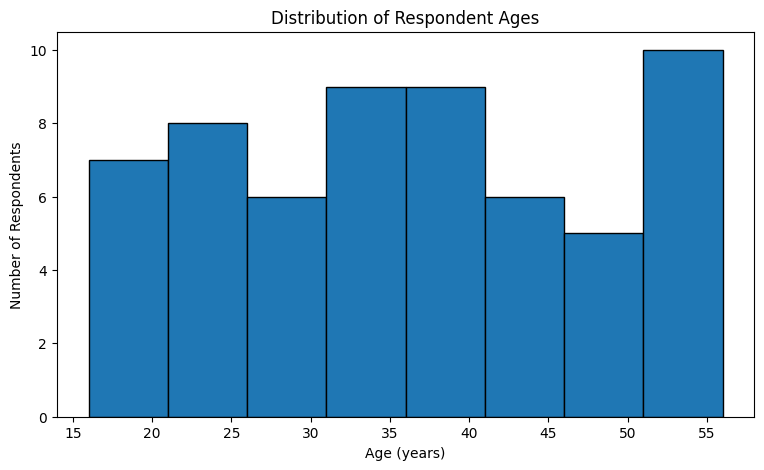

In [16]:
plt.figure(figsize=(9,5))

plt.hist(ndf['Age'], bins=8, edgecolor='black')

plt.title('Distribution of Respondent Ages')
plt.xlabel('Age (years)')
plt.ylabel('Number of Respondents')

plt.show()

**Insights**

1. The age distribution shows that the sample includes respondents from several stages of adulthood, so the analysis is not limited to one narrow age range.
2. This variation in age makes it useful to compare running behavior across age groups, because differences in frequency may be related to where respondents are in their life stage.


# [RQ4: Does age differ across running-frequency groups?](#scrollTo=e8aNrmQz4DEg&line=5&uniqifier=1)

/tmp/ipykernel_3487/1427548425.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data_box, labels=freq_order)


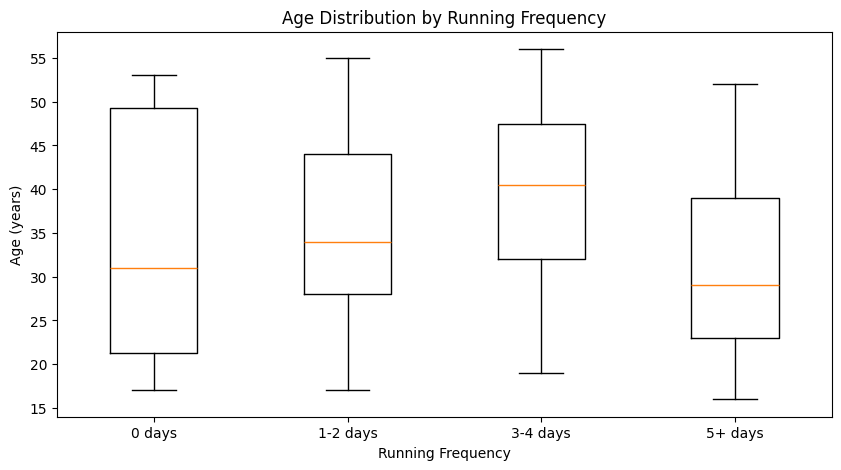

In [17]:
plt.figure(figsize=(10,5))

data_box = [
    ndf.loc[ndf['Running_frequency'] == category, 'Age']
    for category in freq_order
]

plt.boxplot(data_box, labels=freq_order)

plt.title('Age Distribution by Running Frequency')
plt.xlabel('Running Frequency')
plt.ylabel('Age (years)')

plt.show()

In [18]:
age_by_frequency = pd.pivot_table(
    ndf,
    index='Running_frequency',
    values='Age',
    aggfunc=['mean', 'median']
)

age_by_frequency

/tmp/ipykernel_3487/3450169545.py:1: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  age_by_frequency = pd.pivot_table(
/tmp/ipykernel_3487/3450169545.py:1: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  age_by_frequency = pd.pivot_table(


,mean,median
,Age,Age
Running_frequency,,
0 days,34.250000,31.0
1-2 days,36.310345,34.0
3-4 days,39.357143,40.5
5+ days,31.666667,29.0


**Insights**

1. The age distributions are not identical across the running-frequency groups, which suggests that running habits may change with age.
2. At the same time, the overlap between groups indicates that age by itself does not fully explain how often a person runs; respondents of similar ages can still report different running routines.


#[ RQ5: How is running frequency distributed within each age group?](#scrollTo=e8aNrmQz4DEg&line=5&uniqifier=1)

In [19]:
cross = pd.crosstab(
    ndf['AgeGP'],
    ndf['Running_frequency']
).reindex(index=age_order, columns=freq_order)

cross

Running_frequency,0 days,1-2 days,3-4 days,5+ days
AgeGP,,,,
Under 20,2,1,1,1
20-29,2,8,1,4
30-39,1,10,3,2
40+,3,10,9,2


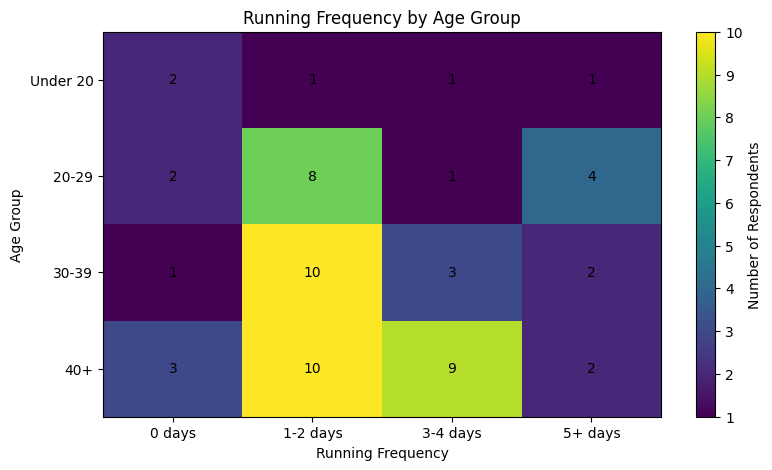

In [20]:
plt.figure(figsize=(9,5))

plt.imshow(cross.values, aspect='auto')

plt.xticks(
    range(len(freq_order)),
    freq_order
)

plt.yticks(
    range(len(age_order)),
    age_order
)

plt.title('Running Frequency by Age Group')
plt.xlabel('Running Frequency')
plt.ylabel('Age Group')

for i in range(len(age_order)):
    for j in range(len(freq_order)):
        plt.text(
            j, i,
            cross.iloc[i, j],
            ha='center',
            va='center'
        )

plt.colorbar(label='Number of Respondents')
plt.show()

**Insights**

1. The heatmap shows that the overall running pattern is not distributed exactly the same way inside every age group, so looking only at the total frequency counts would hide important differences.
2. This helps answer the question by showing that age group changes the composition of running habits, which makes age an important variable for understanding the sample.


# [RQ6: How does average running frequency change across age groups?](#scrollTo=e8aNrmQz4DEg&line=5&uniqifier=1)

In [21]:
avg_score = pd.pivot_table(
    ndf,
    index='AgeGP',
    values='RunScore',
    aggfunc='mean'
).reindex(age_order)

avg_score

/tmp/ipykernel_3487/3855668053.py:1: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  avg_score = pd.pivot_table(


,RunScore
AgeGP,
Under 20,1.200000
20-29,1.466667
30-39,1.375000
40+,1.416667


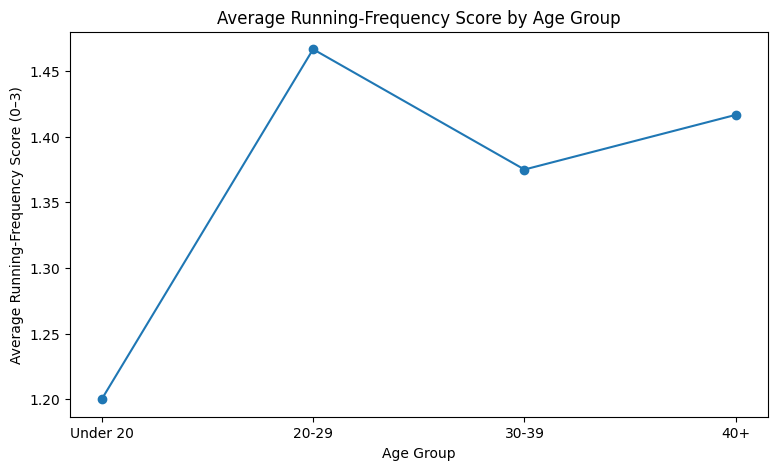

In [22]:
plt.figure(figsize=(9,5))

plt.plot(
    avg_score.index,
    avg_score['RunScore'],
    marker='o'
)

plt.title('Average Running-Frequency Score by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Average Running-Frequency Score (0–3)')

plt.show()

**Insights**

1. The average running-frequency score changes across age groups, showing that the typical running routine is not the same for all ages.
2. This pattern supports the idea that age and running frequency may be associated, although the comparison alone does not prove that age causes the difference.


# [RQ7: Which age group has the highest share of frequent runners?](#scrollTo=e8aNrmQz4DEg&line=5&uniqifier=1)

In [23]:

ndf['FrequentRunner'] = ndf['Running_frequency'].isin(['3-4 days', '5+ days'])

frequent_share = (
    ndf.groupby('AgeGP', observed=False)['FrequentRunner']
       .mean()
       .reindex(age_order) * 100
)

frequent_share

,FrequentRunner
AgeGP,
Under 20,40.000000
20-29,33.333333
30-39,31.250000
40+,45.833333


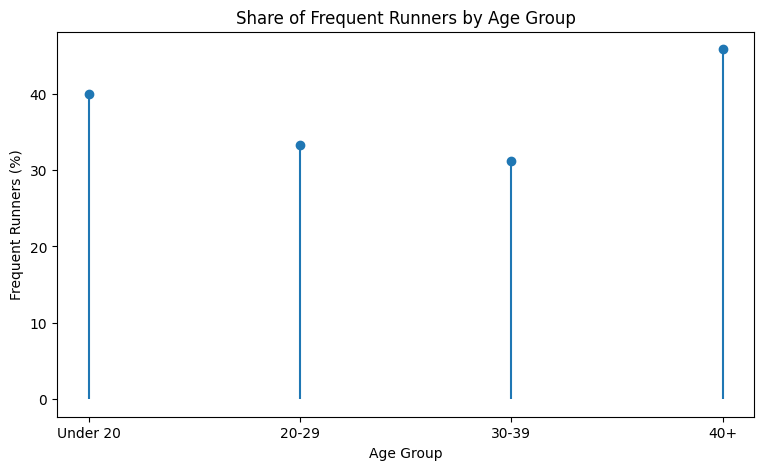

In [24]:
plt.figure(figsize=(9,5))

x = range(len(frequent_share))

plt.vlines(
    x=x,
    ymin=0,
    ymax=frequent_share.values
)

plt.scatter(
    x,
    frequent_share.values
)

plt.xticks(
    x,
    frequent_share.index
)

plt.title('Share of Frequent Runners by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Frequent Runners (%)')

plt.show()

**Insights**

1. The proportion of frequent runners differs by age group, which provides a clearer comparison than using only raw counts because the groups do not have the same number of respondents.
2. This result identifies which age segment is more concentrated in higher-frequency running categories and helps connect age composition with actual running behavior.


# [RQ8: Is age associated with estimated weekly running days?](#scrollTo=e8aNrmQz4DEg&line=5&uniqifier=1)
### Simple Regression Model

**RunDays_est = β₀ + β₁(Age)**

Can age be used to predict running frequency?

- **Dependent variable (Y):** `RunDays_est`
- **Independent variable (X):** `Age`

Because the original frequency variable is categorical, representative weekly-day values are used only to create an exploratory simple regression model.


In [32]:
score_map = {
    '0 days': 0,
    '1-2 days': 1,
    '3-4 days': 2,
    '5+ days': 3
}

ndf['RunScore'] = ndf['Running_frequency'].astype(str).map(score_map).astype(float)

ndf[['Running_frequency', 'RunScore']].head()

,Running_frequency,RunScore
0,3-4 days,2.0
1,1-2 days,1.0
2,3-4 days,2.0
3,1-2 days,1.0
4,3-4 days,2.0


In [33]:
import statsmodels.formula.api as smf

model = smf.ols(
    formula='RunScore ~ Age',
    data=ndf
).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:               RunScore   R-squared:                       0.001
Model:                            OLS   Adj. R-squared:                 -0.016
Method:                 Least Squares   F-statistic:                   0.04802
Date:                Sat, 24 Oct 2026   Prob (F-statistic):              0.827
Time:                        00:02:58   Log-Likelihood:                -78.666
No. Observations:                  60   AIC:                             161.3
Df Residuals:                      58   BIC:                             165.5
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.4793      0.381      3.886      0.0

In [34]:
print(
    f"Regression equation: RunScore = "
    f"{model.params.iloc[0]:.4f} + "
    f"{model.params.iloc[1]:.4f}Age + e"
)

Regression equation: RunScore = 1.4793 + -0.0022Age + e


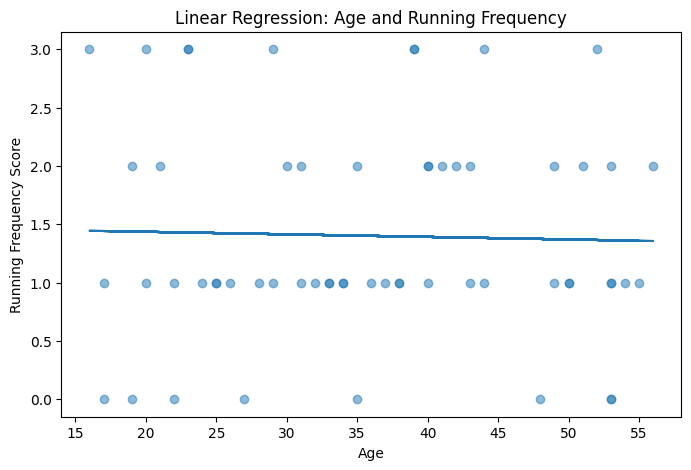

In [35]:
plt.figure(figsize=(8,5))

plt.scatter(
    ndf['Age'],
    ndf['RunScore'],
    alpha=0.5
)

plt.plot(
    ndf['Age'],
    model.fittedvalues
)

plt.title('Linear Regression: Age and Running Frequency')
plt.xlabel('Age')
plt.ylabel('Running Frequency Score')

plt.show()

**Insights**


1. The regression results suggest that age has a relationship with running frequency, but age alone does not completely explain how often respondents run.

2. This means that running habits are likely influenced by other factors in addition to age, so age should be considered as one part of the explanation rather than the only predictor.


# [Final Conclusions](#scrollTo=e8aNrmQz4DEg&line=5&uniqifier=1)

### Final Conclusions

- The sample is concentrated more heavily in older age groups, so the overall running results should be interpreted together with the age-group comparisons rather than only at the total-sample level.
- Running 1–2 days per week is the most common routine, suggesting that moderate or occasional running is more typical than high-frequency running in this sample.
- The age-based studies show that running habits vary across groups, which supports studying age as a possible explanatory factor instead of treating all respondents as one homogeneous population.
- The regression provides a final quantitative view of the relationship between age and estimated weekly running days, while the R-squared helps show how much of the behavior can actually be explained by age.
- An important limitation is that the dataset contains only 60 simulated observations and the original running-frequency variable is categorical, so the regression should be interpreted as exploratory rather than causal.
